In [1]:
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

In [2]:
# Thiết lập seed cố định để đảm bảo tính tái lập (Reproducibility)
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[+] Đang thực thi trên thiết bị: {device}")

# ==============================================================================
# 0. CHUẨN BỊ DỮ LIỆU: BINARIZED MNIST (ẢNH NHỊ PHÂN 28x28)
# ==============================================================================
# Ngưỡng hóa (Thresholding): Pixel > 0.5 -> 1.0 (trắng), ngược lại -> 0.0 (đen)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: (x > 0.5).float())
])

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

[+] Đang thực thi trên thiết bị: cuda


  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<01:13, 135kB/s]

  1%|          | 98.3k/9.91M [00:00<00:56, 173kB/s]

  2%|▏         | 164k/9.91M [00:00<00:47, 204kB/s] 

...

 66%|██████▌   | 1.08M/1.65M [00:01<00:00, 881kB/s]

 97%|█████████▋| 1.61M/1.65M [00:02<00:00, 1.21MB/s]

100%|██████████| 1.65M/1.65M [00:02<00:00, 779kB/s] 

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 7.27MB/s]

Mục tiêu của **Task 1** là tạo ra một **"thực nghiệm phản chứng" (counter-example baseline)** để người học tận mắt chứng kiến sự phá sản của giả định độc lập trong xác suất cổ điển, từ đó hiểu được lý do sống còn vì sao phải dùng Mạng nơ-ron và Chain Rule (Task 2 & 3).

Cụ thể, Task 1 giúp làm rõ vấn đề:

* **Lý thuyết:** Giả định các pixel độc lập giúp số lượng tham số cần lưu trữ từ $2^{784} - 1$ (bất khả thi) xuống chỉ còn $784$ số (cực kỳ gọn nhẹ).
* **Mục tiêu thực hành:** Cho người học thấy "cái giá phải trả" của sự tinh gọn ngây thơ này. Khi triệt tiêu mối tương quan không gian (spatial correlation), mô hình toán học mất hoàn toàn khả năng mô tả thế giới thực.





In [3]:
def train_and_sample_naive_bayes(data_loader, num_samples=16):
    """
    Toán học:
    Mỗi pixel x_i độc lập hoàn toàn: p(x) = prod_{i=1}^{784} p_i^{x_i} (1 - p_i)^{1 - x_i}
    Ước lượng Maximum Likelihood: p_hat_i = (1 / N) * sum_{k=1}^N x_i^{(k)}
    Đây là quy trình **sinh ảnh ngẫu nhiên từ mô hình Naive Bayes** ở mức độ nguyên bản nhất: biến mỗi pixel thành một "đồng xu bị lệch", tung đồng xu độc lập tại từng tọa độ để quyết định pixel đó mang màu trắng hay đen, và lặp lại thao tác này 16 lần để tạo ra 16 bức ảnh mới.
    """
    total_samples = 0
    pixel_sum = torch.zeros((1, 28, 28))

    # Tính tổng tích lũy từng pixel trên toàn bộ tập huấn luyện
    for images, _ in data_loader:
        pixel_sum += images.sum(dim=0)
        total_samples += images.size(0)

    # Vector xác suất tiên nghiệm của 784 pixel
    p_hat = pixel_sum / total_samples
    # Kẹp giá trị để tránh log(0) trong tính toán xác suất
    p_hat = torch.clamp(p_hat, 1e-5, 1.0 - 1e-5)

    # Sinh các ảnh mới bằng cách gieo xúc xắc Bernoulli độc lập tại mỗi tọa độ
    p_expanded = p_hat.expand(num_samples, 1, 28, 28)
    sampled_images = torch.bernoulli(p_expanded)

    return p_hat, sampled_images

p_hat, nb_samples = train_and_sample_naive_bayes(train_loader)


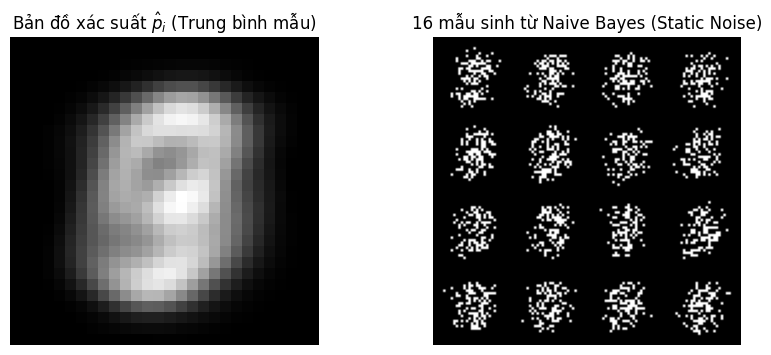

In [4]:
# Trực quan hóa kết quả Naive Bayes
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(p_hat.squeeze().numpy(), cmap="gray")
axes[0].set_title(r"Bản đồ xác suất $\hat{p}_i$ (Trung bình mẫu)")
axes[0].axis("off")

grid_nb = make_grid(nb_samples, nrow=4, padding=2)
axes[1].imshow(grid_nb.permute(1, 2, 0).numpy(), cmap="gray")
axes[1].set_title("16 mẫu sinh từ Naive Bayes (Static Noise)")
axes[1].axis("off")
plt.show()

Phân biệt giữa "Tính trung bình" và "Năng lực tạo sinh" (Triết lý Feynman)

* Khi vẽ bản đồ xác suất trung bình $\hat{p}$, mắt người vẫn nhìn thấy một bóng ma mờ mờ hình chữ số ở giữa. Nhiều người lầm tưởng mô hình đã "học" được dữ liệu.
* Tuy nhiên, khi chuyển sang bước **tạo sinh (sampling)**, kết quả cho ra chỉ là **nhiễu hạt trắng đen (TV static noise)**. Thao tác này khắc sâu câu nói của Richard Feynman trong bài giảng: Nhìn thấy hoặc tính được trung bình không có nghĩa là mô hình đã "hiểu" cấu trúc để tái tạo lại đối tượng.

### 1. $\hat{p}_i$ là gì? (Tỷ lệ pixel bật sáng trong tập dữ liệu)

Trong tập ảnh chữ số viết tay MNIST nhị phân (binarized), mỗi bức ảnh có kích thước $28 \times 28 = 784$ pixel, mỗi pixel $x_i$ chỉ nhận một trong hai giá trị:

* $x_i = 1$ (pixel màu trắng / có nét vẽ)
* $x_i = 0$ (pixel màu đen / nền)

Sau khi duyệt qua toàn bộ $N$ ảnh huấn luyện ($N = 60{,}000$), mô hình tính giá trị trung bình cho từng vị trí pixel thứ $i$ ($i \in [1, 784]$):

$$\hat{p}_i = \frac{1}{N} \sum_{k=1}^N x_i^{(k)}$$

* **Ở 4 góc và viền ảnh:** Hầu như không ai viết số chạm ra mép $\to$ Pixel gần như luôn bằng $0$ $\to$ $\hat{p}_i \approx 0.01$.
* **Ở vùng trung tâm ảnh:** Các nét chữ số thường xuyên đi qua $\to$ $\hat{p}_i$ có thể rơi vào khoảng $0.3 - 0.6$.

---

### 2. $\hat{x}_i \sim \text{Bernoulli}(\hat{p}_i)$ nghĩa là gì?

Phân phối Bernoulli là mô hình toán học của việc **tung một đồng xu bị lệch**:

* Mặt ngửa (pixel trắng $= 1$) với xác suất đúng bằng $\hat{p}_i$.
* Mặt sấp (pixel đen $= 0$) với xác suất $1 - \hat{p}_i$.

Ký hiệu dấu ngã $\sim$ có nghĩa là: **"được rút thăm / lấy mẫu ngẫu nhiên tuân theo quy luật phân phối..."**.

> Thay vì đoán mò, máy tính gieo một số ngẫu nhiên $r \in [0, 1]$:
> * Nếu $r < \hat{p}_i \implies \hat{x}_i = 1$ (chấm màu trắng).
> * Nếu $r \ge \hat{p}_i \implies \hat{x}_i = 0$ (chấm màu đen).
> 
> 

---

### 3. Từ khóa "Độc lập" (Independent) — Lỗi chí mạng của Naive Bayes

Chữ "độc lập" ở đây chính là giả định ngây thơ của Naive Bayes: **Pixel này bật sáng hay tắt không hề quan tâm đến các pixel hàng xóm xung quanh.**

Quy trình tạo ra 1 bức ảnh mới:

1. Đứng ở pixel số 1 (góc trên cùng bên trái) $\to$ Tung đồng xu với xác suất $\hat{p}_1 \to$ Ra màu đen.
2. Bước sang pixel số 2 $\to$ Tung đồng xu với xác suất $\hat{p}_2 \to$ Ra màu đen.
3. ...
4. Bước vào pixel trung tâm số 400 $\to$ Tung đồng xu với xác suất $\hat{p}_{400} = 0.5 \to$ Ra màu trắng.
5. Bước sang pixel số 401 (ngay sát cạnh pixel 400) $\to$ Lại tung đồng xu độc lập với xác suất $\hat{p}_{401} = 0.5 \to$ Ra màu đen.

Vì 784 pixel được tung độc lập, xác suất của toàn bộ bức ảnh bị phân rã thành:

$$p(x) = \prod_{i=1}^{784} p(x_i)$$

---

### 4. Vì sao ảnh sinh ra lại là "nhiễu hạt" (TV Static Noise)?

Nếu hiển thị bản đồ $\hat{p}$ lên màn hình, mắt người nhìn thấy một "bóng ma" lờ mờ của các chữ số từ 0 đến 9 lồng vào nhau ở giữa khung hình.

Tuy nhiên, khi bạn **lấy mẫu ngẫu nhiên độc lập**:

* Hai pixel nằm sát nhau trong nét vẽ của số "1" hoàn toàn không có cơ chế giao tiếp để bảo nhau: *"Này, tôi vừa chọn màu trắng rồi, bạn nằm cạnh tôi cũng phải chọn màu trắng để tạo thành nét thẳng nhé"*.
* Thay vào đó, mỗi pixel tự gieo xúc xắc riêng của mình. Kết quả là tại vùng trung tâm, các pixel trắng đen xen kẽ lộn xộn, tạo ra hình ảnh nhiễu hạt (giống như màn hình tivi mất tín hiệu) tập trung thành một quầng sáng mờ ảo ở giữa, không thể tạo thành bất kỳ nét số liền mạch nào.

Hành động **lấy mẫu 16 ảnh mới** chỉ đơn giản là lặp lại toàn bộ quá trình tung 784 đồng xu độc lập này 16 lần riêng biệt, tạo ra 16 bức ảnh nhiễu hạt khác nhau để xếp thành lưới $4 \times 4$ cho sinh viên quan sát trực quan sự thất bại của giả định độc lập.

Mục đích cốt lõi của **Task 2** là **chuyển hóa quy tắc chuỗi xác suất (Chain Rule) thành một toán tử tính toán khả thi trong không gian 2D**, đảm bảo mạng nơ-ron tuân thủ nghiêm ngặt **tính nhân quả (Causal Constraint)** mà không làm rò rỉ thông tin từ tương lai.

Cụ thể, Task 2 giải quyết 4 mục tiêu kỹ thuật và sư phạm sau:

---

### 1. Triệt tiêu rò rỉ thông tin (Data Leakage) theo thứ tự quét Raster

* **Vấn đề của tích chập thông thường (`nn.Conv2d`):** Kernel tích chập đối xứng tiêu chuẩn luôn nhìn đều về mọi hướng (trên, dưới, trái, phải). Khi tính toán đặc trưng cho vị trí $(h, w)$, mạng sẽ nhìn thấy cả các pixel ở nửa dưới và bên phải — tức các pixel "tương lai" chưa được sinh ra. Điều này vi phạm điều kiện tiên quyết của Chain Rule:

$$p(x) = \prod_{i=1}^{n} p(x_i \mid x_{<i})$$


* **Giải pháp của Masked Convolution:** Mặt nạ (Mask tensor) đặt toàn bộ trọng số ở nửa dưới và phía bên phải về $0$. Nhờ đó, receptive field của mạng tại tọa độ $(h, w)$ bị khóa cứng, chỉ được phép thu nhận thông tin từ các pixel "quá khứ" $x_{<i}$ (các hàng phía trên hoặc các cột bên trái cùng hàng).

---

### 2. Ngăn chặn nghiệm tầm thường qua phân định Mask Type A và Type B

Đây là chi tiết kiến trúc quan trọng nhất mà sinh viên cần nắm:

* **Mask Type A (Tâm $= 0$, chỉ dùng cho lớp đầu tiên):**
* Ở lớp đầu, đầu vào là ảnh gốc $x$. Nếu cho phép trọng số tại tâm khác $0$, pixel đầu ra tại $(h, w)$ sẽ nhìn thấy trực tiếp giá trị của pixel đầu vào $(h, w)$.
* Khi đó, mạng sẽ rơi vào bẫy **học vẹt (trivial identity mapping)**: chỉ cần truyền thẳng giá trị $x_i \to \hat{x}_i$ là loss đã bằng $0$, mà không cần học mối tương quan ngữ cảnh từ các pixel trước đó. Do đó, tâm bắt buộc phải bằng $0$.


* **Mask Type B (Tâm $= 1$, dùng cho tất cả các lớp ẩn tiếp theo):**
* Từ lớp thứ hai trở đi, giá trị tại tâm không còn là pixel gốc $x_i$ nữa. Do đã đi qua Mask A ở lớp 1, giá trị này thực chất là một vector đặc trưng ẩn chỉ chứa thông tin tổng hợp từ quá khứ $x_{<i}$.
* Lúc này, việc giữ tâm $= 1$ là bắt buộc để mạng có thể tiếp tục xử lý, tinh chỉnh và truyền tải thông tin ngữ cảnh đó xuống các tầng sâu hơn mà không làm đứt gãy luồng biểu diễn.



---

### 3. Mở khóa năng lực huấn luyện song song (Parallel Training)

* Mặc dù quá trình **sinh ảnh (sampling)** ở Task 3 diễn ra tuần tự từng pixel ($O(D)$), nhưng quá trình **huấn luyện (training)** lại có thể chạy **song song hoàn toàn trên toàn bộ bức ảnh** chỉ qua một lượt Forward duy nhất.
* Nhờ có mặt nạ nhân quả được "khắc" trực tiếp lên kernel, ta có thể ném toàn bộ bức ảnh $28 \times 28$ vào mạng cùng lúc. Mạng sẽ tính toán đồng thời 784 giá trị logit dự đoán cho 784 pixel mà vẫn đảm bảo tính độc lập nhân quả ở từng vị trí. Cơ chế này tương đồng hoàn toàn với **Causal Masked Self-Attention** trong các mô hình ngôn ngữ lớn (như GPT).

---

### 4. Đóng gói khối module (Building Block) chuẩn cho Task 3

* Task 2 cung cấp một lớp kế thừa sạch sẽ từ `nn.Conv2d`, đăng ký `mask` dưới dạng `buffer` (để tự động chuyển theo thiết bị CPU/GPU cùng model nhưng không tính đạo hàm).
* Phần unit test trực quan hóa ma trận $7 \times 7$ giúp sinh viên nhìn thấy hình ảnh cụ thể của ma trận nhị phân 0-1, tự kiểm tra mã nguồn (sanity check) trước khi đưa vào ráp nối toàn bộ mạng `ToyPixelCNN` ở Task 3.


TASK 2: Cài đặt và Kiểm tra Masked Convolution


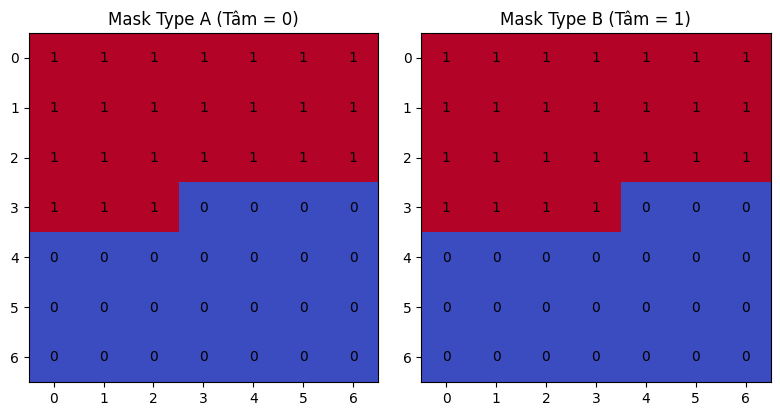

In [5]:
# ==============================================================================
# TASK 2: CÀI ĐẶT LỚP TÍCH CHẬP CHE MẶT NẠ (MASKED CONVOLUTION)
# ==============================================================================
print("\n" + "="*50)
print("TASK 2: Cài đặt và Kiểm tra Masked Convolution")
print("="*50)

class MaskedConv2d(nn.Conv2d):
    """
    Lớp tích chập có mặt nạ bảo toàn tính nhân quả (Causal Constraint):
    - Type A: Che toàn bộ nửa dưới, bên phải và CHÍNH PIXEL TRUNG TÂM (dùng cho lớp đầu).
    - Type B: Che toàn bộ nửa dưới và bên phải, NHƯNG GIỮ LẠI TRUNG TÂM (dùng cho các lớp sau).
    """
    def __init__(self, mask_type, in_channels, out_channels, kernel_size=7, stride=1, padding=3, bias=True):
        super().__init__(in_channels, out_channels, kernel_size, stride, padding, bias=bias)
        assert mask_type in ['A', 'B'], "mask_type phải là 'A' hoặc 'B'"
        self.mask_type = mask_type

        # Đăng ký mask dưới dạng buffer (không cập nhật gradient)
        self.register_buffer('mask', torch.ones_like(self.weight))
        
        _, _, kh, kw = self.weight.shape
        center_h, center_w = kh // 2, kw // 2

        # 1. Che toàn bộ các hàng phía dưới tâm
        self.mask[:, :, center_h + 1:, :] = 0.0
        # 2. Che các cột bên phải tâm trên chính hàng tâm
        self.mask[:, :, center_h, center_w + 1:] = 0.0
        # 3. Nếu là Mask Type A: che luôn pixel tâm
        if mask_type == 'A':
            self.mask[:, :, center_h, center_w] = 0.0

    def forward(self, x):
        # Nhân trọng số với mask thông qua F.conv2d để luồng tính gradient hoạt động mượt mà
        masked_weight = self.weight * self.mask
        return F.conv2d(x, masked_weight, self.bias, self.stride, self.padding, self.dilation, self.groups)

# Unit test kiểm tra trực quan mặt nạ kernel 7x7
test_conv_a = MaskedConv2d('A', 1, 1, kernel_size=7, padding=3)
test_conv_b = MaskedConv2d('B', 1, 1, kernel_size=7, padding=3)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(test_conv_a.mask[0, 0].cpu().numpy(), cmap='coolwarm', vmin=0, vmax=1)
axes[0].set_title("Mask Type A (Tâm = 0)")
for (j, i), label in np.ndenumerate(test_conv_a.mask[0, 0].cpu().numpy()):
    axes[0].text(i, j, int(label), ha='center', va='center', color='black')

axes[1].imshow(test_conv_b.mask[0, 0].cpu().numpy(), cmap='coolwarm', vmin=0, vmax=1)
axes[1].set_title("Mask Type B (Tâm = 1)")
for (j, i), label in np.ndenumerate(test_conv_b.mask[0, 0].cpu().numpy()):
    axes[1].text(i, j, int(label), ha='center', va='center', color='black')

plt.tight_layout()
plt.show()

Mục tiêu của **Task 3** gói gọn trong **3 điểm cốt lõi**:

1. **Kiểm chứng sức mạnh tạo hình của Chain Rule:**
* Chứng minh rằng khi các pixel được điều kiện hóa lên nhau qua mạng nơ-ron sâu ($p(x_i \mid x_{<i})$), ảnh sinh ra sẽ có cấu trúc nét vẽ rõ ràng (số '0', '3', '8'...), đập tan hoàn toàn hiện tượng nhiễu hạt rời rạc của Naive Bayes ở Task 1.


2. **Thực hành tối ưu hóa Log-Likelihood chính xác (Tractable Exact Likelihood):**
* Huấn luyện mạng bằng hàm `BCEWithLogitsLoss` để cực đại hóa trực tiếp $\sum \log p_\theta(x_i \mid x_{<i})$ trên toàn bộ ảnh trong một lượt chạy song song duy nhất (Teacher Forcing), không cần qua bất kỳ xấp xỉ hay cận dưới nào.


3. **Tận mắt nếm trải "Điểm nghẽn tuần tự" (Sequential Bottleneck):**
* Cho sinh viên tự đo thời gian chạy của vòng lặp lấy mẫu: mất hàng chục giây chỉ để sinh ra 16 ảnh nhỏ $28 \times 28$ vì phải chạy tuần tự $784$ lần forward pass ($O(D)$).
* Trải nghiệm này trả lời câu hỏi: *Vì sao Autoregressive thất bại trên ảnh độ phân giải cao và tại sao chúng ta phải học VAE, GAN hay Diffusion ở các buổi tiếp theo.*

In [6]:
print("\n" + "="*50)
print("TASK 3: Huấn luyện Toy PixelCNN & Trải nghiệm Sampling Bottleneck")
print("="*50)

class ToyPixelCNN(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()
        layers = [
            MaskedConv2d('A', 1, hidden_dim, kernel_size=7, padding=3),
            nn.ReLU(inplace=True)
        ]
        # Xếp chồng 6 lớp Mask B để phủ kín toàn bộ ảnh 28x28
        for _ in range(6):
            layers.extend([
                MaskedConv2d('B', hidden_dim, hidden_dim, kernel_size=7, padding=3),
                nn.ReLU(inplace=True)
            ])
        layers.append(nn.Conv2d(hidden_dim, 1, kernel_size=1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Khởi tạo mô hình, hàm mất mát và bộ tối ưu hóa
model = ToyPixelCNN(hidden_dim=64).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Huấn luyện mô hình trong 3 epoch để sinh viên quan sát loss giảm nhanh
EPOCHS = 10
print(f"[+] Bắt đầu huấn luyện Toy PixelCNN trong {EPOCHS} epochs...")

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for step, (images, _) in enumerate(train_loader):
        images = images.to(device)
        optimizer.zero_grad()
        
        # Forward pass: dự đoán phân phối nhị phân của từng pixel
        logits = model(images)
        loss = criterion(logits, images)
        
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    print(f"Epoch [{epoch}/{EPOCHS}] - Binary Cross-Entropy Loss: {avg_loss:.4f}")



TASK 3: Huấn luyện Toy PixelCNN & Trải nghiệm Sampling Bottleneck


[+] Bắt đầu huấn luyện Toy PixelCNN trong 10 epochs...


Epoch [1/10] - Binary Cross-Entropy Loss: 0.1205


Epoch [2/10] - Binary Cross-Entropy Loss: 0.0837


Epoch [3/10] - Binary Cross-Entropy Loss: 0.0820


...

Epoch [6/10] - Binary Cross-Entropy Loss: 0.0783


Epoch [7/10] - Binary Cross-Entropy Loss: 0.0777


Epoch [8/10] - Binary Cross-Entropy Loss: 0.0772


Epoch [9/10] - Binary Cross-Entropy Loss: 0.0767


Epoch [10/10] - Binary Cross-Entropy Loss: 0.0762



[+] Bắt đầu quá trình lấy mẫu tuần tự cho 16 ảnh...


[+] Hoàn tất sinh mẫu trong: 2.48 giây!
[!] Tốc độ trung bình: 0.0032 giây/pixel.


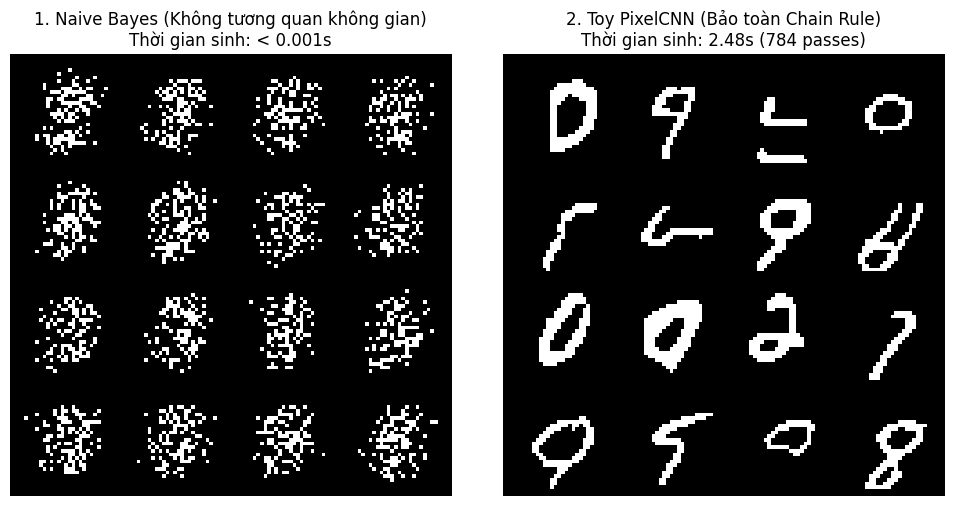

In [7]:

def sample_pixelcnn(model, num_samples=16):
    """
    Sinh mẫu tuần tự từng pixel theo thứ tự Raster Scan:
    Độ phức tạp tính toán: O(D) = 28 x 28 = 784 forward passes!
    """
    model.eval()
    # Đầu vào là một chuỗi số ngẫu nhiên vô nghĩa
    samples = torch.zeros((num_samples, 1, 28, 28), device=device)
    
    print(f"\n[+] Bắt đầu quá trình lấy mẫu tuần tự cho {num_samples} ảnh...")
    start_time = time.time()
    
    with torch.no_grad():
        for h in range(28):
            for w in range(28):
                # 1. Chạy Forward pass trên toàn bộ canvas hiện tại
                logits = model(samples)
                
                # 2. Lấy xác suất tại tọa độ (h, w)
                temperature = 0.7
                probs = torch.sigmoid(logits[:, :, h, w] / temperature)     
                           
                # 3. Gieo xúc xắc Bernoulli để lấy giá trị nhị phân {0, 1}
                sampled_pixel = torch.bernoulli(probs)
                
                # 4. Gán giá trị vào ảnh và tiếp tục bước tiếp theo
                samples[:, :, h, w] = sampled_pixel

    elapsed_time = time.time() - start_time
    print(f"[+] Hoàn tất sinh mẫu trong: {elapsed_time:.2f} giây!")
    print(f"[!] Tốc độ trung bình: {elapsed_time / (28 * 28):.4f} giây/pixel.")
    
    return samples.cpu(), elapsed_time

pixelcnn_samples, inference_duration = sample_pixelcnn(model, num_samples=16)

# Trực quan hóa so sánh trực diện
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Kết quả Naive Bayes
grid_nb = make_grid(nb_samples, nrow=4, padding=2)
axes[0].imshow(grid_nb.permute(1, 2, 0).numpy(), cmap="gray")
axes[0].set_title("1. Naive Bayes (Không tương quan không gian)\nThời gian sinh: < 0.001s")
axes[0].axis("off")

# Kết quả Toy PixelCNN
grid_cnn = make_grid(pixelcnn_samples, nrow=4, padding=2)
axes[1].imshow(grid_cnn.permute(1, 2, 0).numpy(), cmap="gray")
axes[1].set_title(f"2. Toy PixelCNN (Bảo toàn Chain Rule)\nThời gian sinh: {inference_duration:.2f}s (784 passes)")
axes[1].axis("off")

plt.tight_layout()
plt.show()